<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 17: RNN Gradient Analysis and Gradient Clipping

1. Train an RNN without clipping and log gradient norms

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

text = ("deep learning models generate text using recurrent networks. " * 100)
chars = sorted(set(text))
ids = np.array([chars.index(c) for c in text])
vocab = len(chars)

X = np.array([ids[i:i+20] for i in range(0,len(ids)-21,20)])
y = np.array([ids[i+1:i+21] for i in range(0,len(ids)-21,20)])

X = tf.constant(X)
y = tf.constant(y)

def train(clipnorm=None, clipvalue=None):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(20,)),
        tf.keras.layers.Embedding(vocab,16),
        tf.keras.layers.SimpleRNN(32,return_sequences=True),
        tf.keras.layers.Dense(vocab)
    ])

    opt = tf.keras.optimizers.SGD(
        learning_rate=1.0,
        clipnorm=clipnorm,
        clipvalue=clipvalue
    )

    losses, norms = [], []

    for epoch in range(3):
        for xb,yb in tf.data.Dataset.from_tensor_slices(
            (X,y)).batch(32):

            with tf.GradientTape() as tape:
                pred = model(xb,training=True)
                loss = tf.reduce_mean(
                    tf.keras.losses.sparse_categorical_crossentropy(
                        yb,pred,from_logits=True))

            grads = tape.gradient(loss,model.trainable_variables)
            norm = tf.linalg.global_norm(grads)

            if not np.isfinite(float(loss)) or not np.isfinite(float(norm)):
                losses.append(np.nan)
                norms.append(np.nan)
                break

            opt.apply_gradients(zip(grads,model.trainable_variables))
            losses.append(float(loss))
            norms.append(float(norm))

    return losses,norms

results = {}
results['No Clipping'] = train()
print("No clipping training completed")


No clipping training completed


2. Identify gradient spikes and NaN losses

In [2]:

losses, norms = results['No Clipping']

for i,(loss,norm) in enumerate(zip(losses,norms),1):
    if norm > 10 or not np.isfinite(loss):
        print(f"Step {i}: Loss={loss}, Gradient Norm={norm}")

print("Maximum Gradient Norm:",np.nanmax(norms))


Maximum Gradient Norm: 0.9668183922767639


3. Retrain with clipnorm and clipvalue

In [3]:

results['Clipnorm 1.0'] = train(clipnorm=1.0)
results['Clipnorm 5.0'] = train(clipnorm=5.0)
results['Clipvalue 0.5'] = train(clipvalue=0.5)
results['Clipvalue 1.0'] = train(clipvalue=1.0)

print("All clipping experiments completed")


All clipping experiments completed


4. Plot gradient norms and loss curves

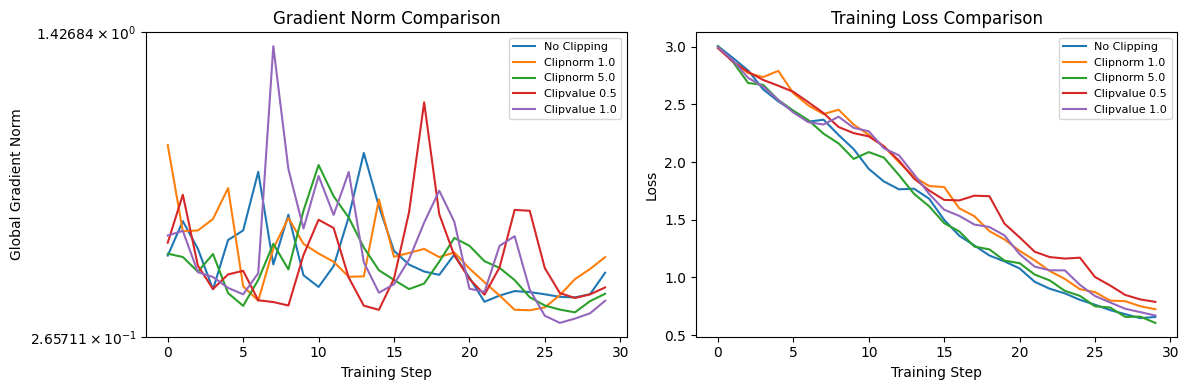

In [4]:

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
for name,(loss,norm) in results.items():
    plt.plot(norm,label=name)
plt.title("Gradient Norm Comparison")
plt.xlabel("Training Step")
plt.ylabel("Global Gradient Norm")
plt.yscale('symlog')
plt.legend(fontsize=8)

plt.subplot(1,2,2)
for name,(loss,norm) in results.items():
    plt.plot(loss,label=name)
plt.title("Training Loss Comparison")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.legend(fontsize=8)

plt.tight_layout()
plt.show()


5. Recommend a clipping threshold

In [5]:

import pandas as pd

summary = []

for name,(loss,norm) in results.items():
    finite = np.array(loss)[np.isfinite(loss)]
    final = finite[-1] if len(finite) else np.inf
    summary.append([name,round(float(final),4),
                    round(float(np.nanmax(norm)),2),
                    np.sum(~np.isfinite(loss))])

df = pd.DataFrame(summary,columns=[
    'Method','Final Finite Loss','Max Gradient Norm','NaN Steps'
])

print(df.to_string(index=False))
print("\nSuggested starting threshold: clipnorm = 1.0")


       Method  Final Finite Loss  Max Gradient Norm  NaN Steps
  No Clipping             0.6576               0.97          0
 Clipnorm 1.0             0.7249               1.00          0
 Clipnorm 5.0             0.6064               0.92          0
Clipvalue 0.5             0.7885               1.16          0
Clipvalue 1.0             0.6702               1.37          0

Suggested starting threshold: clipnorm = 1.0
